# Institutional Client Trades, Pricing, Risk & ML

**An end-to-end, hands-on quantitative case study with simulated data**

> **Scenario:** A bank serves institutional clients trading bonds, equity futures and FX forwards. You must identify attractive/problematic trades, price instruments, quantify risk, assess client suitability, and build an auditable analytical tool.

**Target:** Senior Python / Quant / ML / AI Engineer interviews, including live coding, data analysis, quantitative reasoning and system design.

**Duration:** ~5–8 hours of guided work, plus 3–4 hours of exercises. You can rerun every section independently **after** running all setup cells above it. All data is synthetic, deterministic under the seed and **not investment advice**.

## Interview story in 40 seconds

1. **Define business outcome:** better client trade decisions, lower execution cost, manageable portfolio risk, no suitability breach.
2. **Clarify data:** reference data, market quotes, curve inputs, client positions, mandate/limits, fills, realized outcomes.
3. **Build pricing baseline:** independently compute fair value and compare with actual execution.
4. **Quantify decisions:** expected edge, execution cost, incremental VaR, stress exposure, liquidity and client suitability.
5. **Validate:** time-aware baselines, backtests, unit tests, sensitivity analysis and reviewable explanations.
6. **Productionise:** lineage, timestamp alignment, model monitoring, auditability and human approval.

## Navigation

| Module | Interview capability | Main visual |
|---|---|---|
| 1. Simulate market and client data | pandas, NumPy, joins, reproducibility | Market regime charts |
| 2. Pricing engines | functions, vectorisation, unit tests | Bond/forward sensitivities |
| 3. Trade assessment and EDA | grouping, features, outliers | Execution quality dashboard |
| 4. Portfolio and client suitability | covariance, VaR, stress, constraints | Risk comparison and client ranking |
| 5. Predict problem trades | sklearn, time split, classification | PR curve/confusion matrix |
| 6. Hedge design | duration, DV01, hedge ratio | Hedged vs unhedged P&L |
| 7. Monitoring and API thinking | rolling signals, controls, interviews | Operational monitoring |
| 8. Coding challenge and solutions | hands-on Python practice | Tests and answer key |

**Notation:** 1 basis point (bp) = 0.01 percentage point = 0.0001; positive `side=+1` is buy/long and `side=-1` is sell/short. Unless stated, USD amounts are used for comparison. Product pricing is intentionally simplified to teach method, not to represent production valuation.

## 0 — Environment and habits

Dependencies: `numpy`, `pandas`, `matplotlib`, `seaborn`, `scipy`, `scikit-learn` (standard Anaconda/Jupyter data-science stack). No internet, external files or API keys are needed.

Interview technique: in every analytical task say (a) what you are measuring, (b) the units, (c) the simplifying assumptions, (d) the baseline, and (e) the control you would add in production.

In [1]:
import warnings
from dataclasses import dataclass
from time import perf_counter
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import norm
from sklearn.compose import ColumnTransformer
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (ConfusionMatrixDisplay, average_precision_score,
                             classification_report, precision_recall_curve,
                             roc_auc_score, brier_score_loss)
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

SEED = 42
rng = np.random.default_rng(SEED)
pd.set_option('display.max_columns', 28)
pd.set_option('display.width', 140)
pd.options.display.float_format = '{:,.4f}'.format
sns.set_theme(style='whitegrid', palette='deep')
plt.rcParams.update({'figure.figsize': (11, 4.3), 'axes.titlesize': 12})
print('Ready: numpy', np.__version__, '| pandas', pd.__version__)

Ready: numpy 2.3.5 | pandas 2.2.3


mkdir -p failed for path /root/.config/matplotlib: [Errno 30] Read-only file system: '/root/.config'
Matplotlib created a temporary cache directory at /tmp/matplotlib-02mmkzhs because there was an issue with the default path (/root/.config/matplotlib); it is highly recommended to set the MPLCONFIGDIR environment variable to a writable directory, in particular to speed up the import of Matplotlib and to better support multiprocessing.


## 1 — Simulate correlated market conditions and client mandates

**Why simulate correlation?** Real trades are exposed to shared drivers: equity returns, interest rates, FX and credit spreads. Treating these shocks as independent would understate or overstate risk.

We generate 300 business days with mild regime change. The factor units are deliberately mixed:

- `equity_ret`: fractional daily equity return (0.01 = +1%).
- `rates_bp`: daily government-yield change in bp (+10 = +10 bp).
- `fx_ret`: fractional daily move in GBP/USD.
- `credit_bp`: daily credit-spread change in bp.

We use a **positive-semidefinite covariance by construction**: factor shocks = independent Gaussian shocks × Cholesky factor. This avoids making up an invalid correlation matrix.

In [2]:
dates = pd.bdate_range('2025-01-02', periods=300)
base_corr = np.array([[1.0, 0.18, 0.20, -0.45],
                      [0.18, 1.0, -0.16, 0.26],
                      [0.20, -0.16, 1.0, -0.10],
                      [-0.45, 0.26, -0.10, 1.0]])
assert np.linalg.eigvalsh(base_corr).min() > 0
daily_scale = np.array([0.011, 5.5, 0.0055, 3.2])
shocks = rng.normal(size=(len(dates), 4)) @ np.linalg.cholesky(base_corr).T
shocks *= daily_scale
shocks[190:] *= np.array([1.45, 1.35, 1.3, 1.65])  # later volatility regime
factors = pd.DataFrame(shocks, index=dates,
                       columns=['equity_ret', 'rates_bp', 'fx_ret', 'credit_bp'])
factors.index.name = 'date'
market = factors.copy()
market['us_equity_spot'] = 5_000 * (1 + market.equity_ret).cumprod()
market['uk_equity_spot'] = 7_500 * (1 + 0.75 * market.equity_ret +
                                   rng.normal(0, 0.003, len(market))).cumprod()
market['gbpusd'] = 1.26 * (1 + market.fx_ret).cumprod()
market['eurusd'] = 1.09 * (1 + 0.72 * market.fx_ret +
                           rng.normal(0, 0.0025, len(market))).cumprod()
market['gbp_rate'] = (0.041 + market.rates_bp.cumsum() / 10_000).clip(0.005, 0.09)
market['usd_rate'] = (0.047 + 0.8 * market.rates_bp.cumsum() / 10_000).clip(0.005, 0.10)
market['credit_spread'] = (0.011 + market.credit_bp.cumsum() / 10_000).clip(0.003, 0.045)
display(market.head(3))

,equity_ret,rates_bp,fx_ret,credit_bp,us_equity_spot,uk_equity_spot,gbpusd,eurusd,gbp_rate,usd_rate,credit_spread
date,,,,,,,,,,,
2025-01-02,0.0034,-5.3248,0.0054,1.0255,"5,016.7594","7,489.0972",1.2668,1.0927,0.0405,0.0466,0.0111
2025-01-03,-0.0215,-8.9765,-0.0000,0.5596,"4,909.0928","7,357.6289",1.2668,1.0910,0.0396,0.0459,0.0112
2025-01-06,-0.0002,-4.6317,0.0056,1.2938,"4,908.1856","7,365.8847",1.2738,1.0990,0.0391,0.0455,0.0113


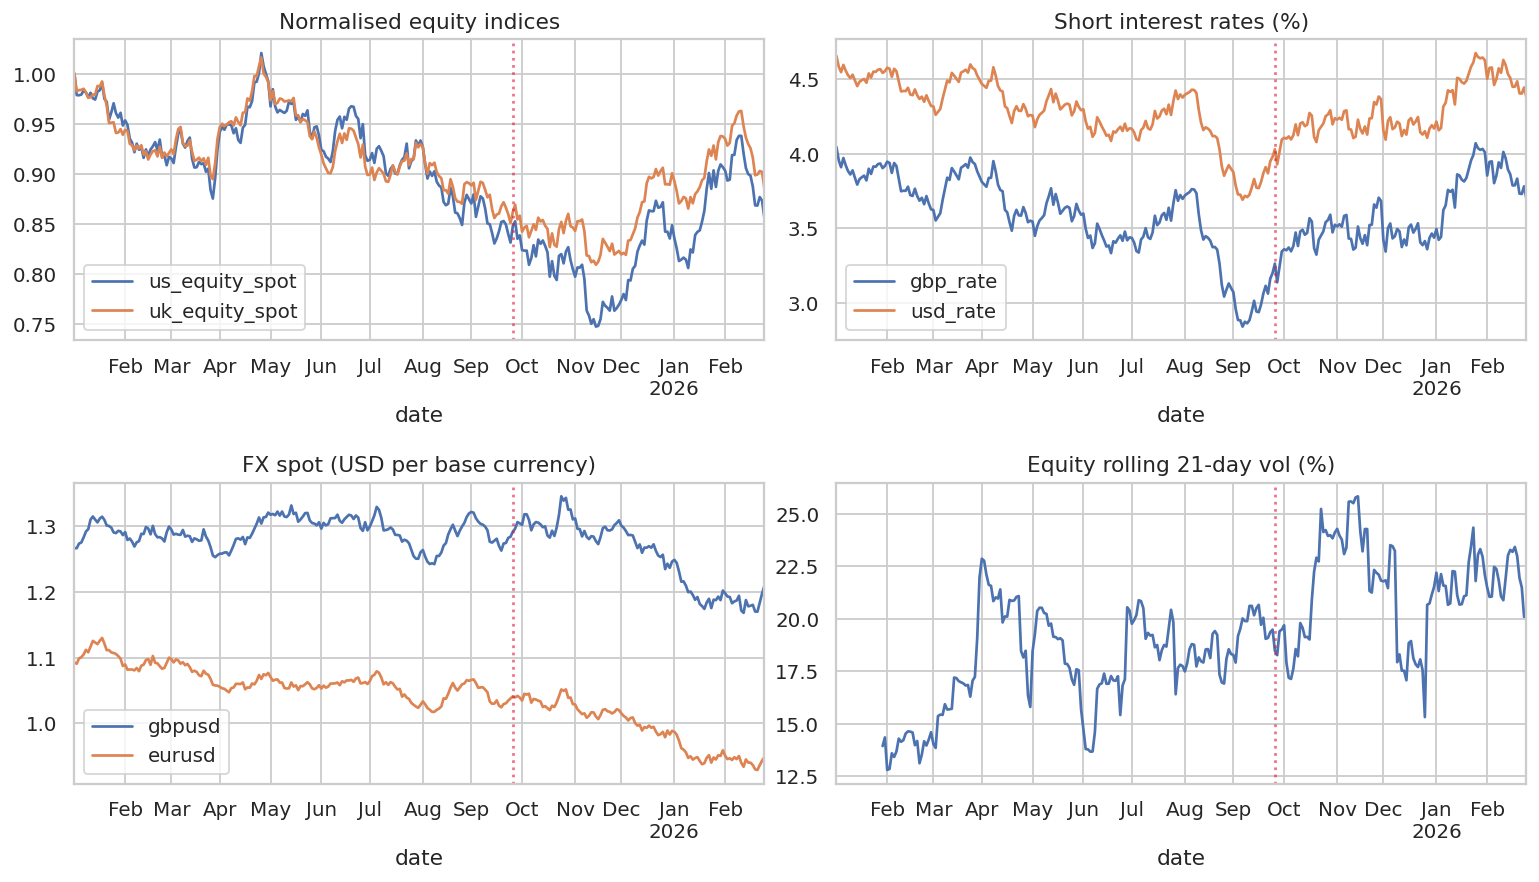

In [3]:
fig, axes = plt.subplots(2, 2, figsize=(12, 7))
market[['us_equity_spot', 'uk_equity_spot']].div(market[['us_equity_spot','uk_equity_spot']].iloc[0]).plot(ax=axes[0,0], title='Normalised equity indices')
market[['gbp_rate','usd_rate']].mul(100).plot(ax=axes[0,1], title='Short interest rates (%)')
market[['gbpusd','eurusd']].plot(ax=axes[1,0], title='FX spot (USD per base currency)')
market.equity_ret.rolling(21).std().mul(np.sqrt(252)*100).plot(ax=axes[1,1], title='Equity rolling 21-day vol (%)')
for ax in axes.flat: ax.axvline(dates[190], linestyle=':', color='crimson', alpha=.6)
fig.tight_layout(); plt.show()

### Client models are not just ML models

A **client model** is a structured representation of investment objective, approved asset classes, existing exposures, limits, liquidity needs and review requirements. It provides hard constraints around any quantitative recommendation. The examples below are fictitious.

In [4]:
clients = pd.DataFrame([
    ('C001','Pension Scheme','Income & hedge','BOND|FX',3.4e6,160e6,0.50,'Low'),
    ('C002','Macro Fund','Tactical alpha','BOND|FUTURE|FX',5.5e6,230e6,0.65,'High'),
    ('C003','Insurance Group','Liability matching','BOND|FX',3.2e6,180e6,0.40,'Low'),
    ('C004','Endowment','Diversified growth','BOND|FUTURE|FX',4.0e6,180e6,0.55,'Medium'),
    ('C005','Asset Manager','Tactical alpha','FUTURE|FX',3.5e6,150e6,0.65,'High'),
    ('C006','Corporate Treasury','FX hedge','BOND|FX',2.4e6,110e6,0.55,'Low'),
    ('C007','Sovereign Investor','Diversified growth','BOND|FUTURE|FX',7.0e6,300e6,0.70,'High'),
    ('C008','Family Office','Income & hedge','BOND|FUTURE|FX',2.8e6,115e6,0.45,'Medium'),
], columns=['client_id','client_name','objective','approved_products','var_limit_usd',
            'gross_limit_usd','single_product_max_share','risk_appetite'])
display(clients)

,client_id,client_name,objective,approved_products,var_limit_usd,gross_limit_usd,single_product_max_share,risk_appetite
0,C001,Pension Scheme,Income & hedge,BOND|FX,"3,400,000.0000","160,000,000.0000",0.5000,Low
1,C002,Macro Fund,Tactical alpha,BOND|FUTURE|FX,"5,500,000.0000","230,000,000.0000",0.6500,High
2,C003,Insurance Group,Liability matching,BOND|FX,"3,200,000.0000","180,000,000.0000",0.4000,Low
3,C004,Endowment,Diversified growth,BOND|FUTURE|FX,"4,000,000.0000","180,000,000.0000",0.5500,Medium
4,C005,Asset Manager,Tactical alpha,FUTURE|FX,"3,500,000.0000","150,000,000.0000",0.6500,High
5,C006,Corporate Treasury,FX hedge,BOND|FX,"2,400,000.0000","110,000,000.0000",0.5500,Low
6,C007,Sovereign Investor,Diversified growth,BOND|FUTURE|FX,"7,000,000.0000","300,000,000.0000",0.7000,High
7,C008,Family Office,Income & hedge,BOND|FUTURE|FX,"2,800,000.0000","115,000,000.0000",0.4500,Medium


## 2 — Price three product families

The interview focus is **explainable and testable pricing**, with units and conventions specified.

1. **Fixed-rate bond:** coupon PV plus principal PV, using a flat annual yield with semi-annual coupons. `price` is per 100 par, clean/dirty and accrued-interest distinctions are omitted. For non-integer coupon periods we round to the nearest period as a teaching simplification.

   \(P(y)=\sum_{i=1}^{n}\frac{100c/f}{(1+y/f)^i}+\frac{100}{(1+y/f)^n}\)

2. **Equity future:** continuous carry, \(F=S e^{(r-q)T}\), ignoring basis, margin funding differences and discrete dividends.
3. **FX forward:** simple covered-interest-parity approximation for spot quoted as USD per unit of base currency, \(F=S\frac{1+r_{USD}T}{1+r_{base}T}\). True dealer curves, collateral and cross-currency basis are omitted.

Your interview response should always distinguish **model fair value**, **tradable bid/ask** and **actual executed price**.

In [5]:
def bond_price_100(coupon_rate: float, annual_yield: float, years: float, frequency: int = 2) -> float:
    '''PV per 100 par, fixed coupon, flat yield, coupon timing simplified.'''
    if years <= 0 or frequency < 1 or annual_yield <= -frequency:
        raise ValueError('invalid maturity, frequency or yield')
    n = max(1, round(years * frequency))
    t = np.arange(1, n + 1)
    return float(np.sum(100 * coupon_rate / frequency / (1 + annual_yield / frequency)**t)
                 + 100 / (1 + annual_yield / frequency)**n)

def bond_modified_duration(coupon: float, yld: float, years: float) -> float:
    '''Modified duration using central finite difference; annual-yield units.'''
    dy = 1e-4
    p = bond_price_100(coupon, yld, years)
    return (bond_price_100(coupon, yld-dy, years) -
            bond_price_100(coupon, yld+dy, years)) / (2 * p * dy)

def future_fair(spot: float, rate: float, dividend_yield: float, years: float) -> float:
    if spot <= 0 or years < 0: raise ValueError('invalid spot or tenor')
    return float(spot * np.exp((rate - dividend_yield) * years))

def fx_forward_fair(spot: float, base_rate: float, quote_rate: float, years: float) -> float:
    if spot <= 0 or years < 0 or 1 + base_rate * years <= 0:
        raise ValueError('invalid spot, tenor or discount factor')
    return float(spot * (1 + quote_rate * years) / (1 + base_rate * years))

assert abs(bond_price_100(.04, .04, 5) - 100) < 1e-8
assert bond_price_100(.04, .055, 5) < bond_price_100(.04, .04, 5)
assert abs(future_fair(100, 0, 0, 1)-100) < 1e-8
assert abs(fx_forward_fair(1.25, .04, .04, 1)-1.25) < 1e-8
print('Pricing invariants passed; sample 5Y bond duration:',round(bond_modified_duration(.04,.045,5),2))

Pricing invariants passed; sample 5Y bond duration: 4.47


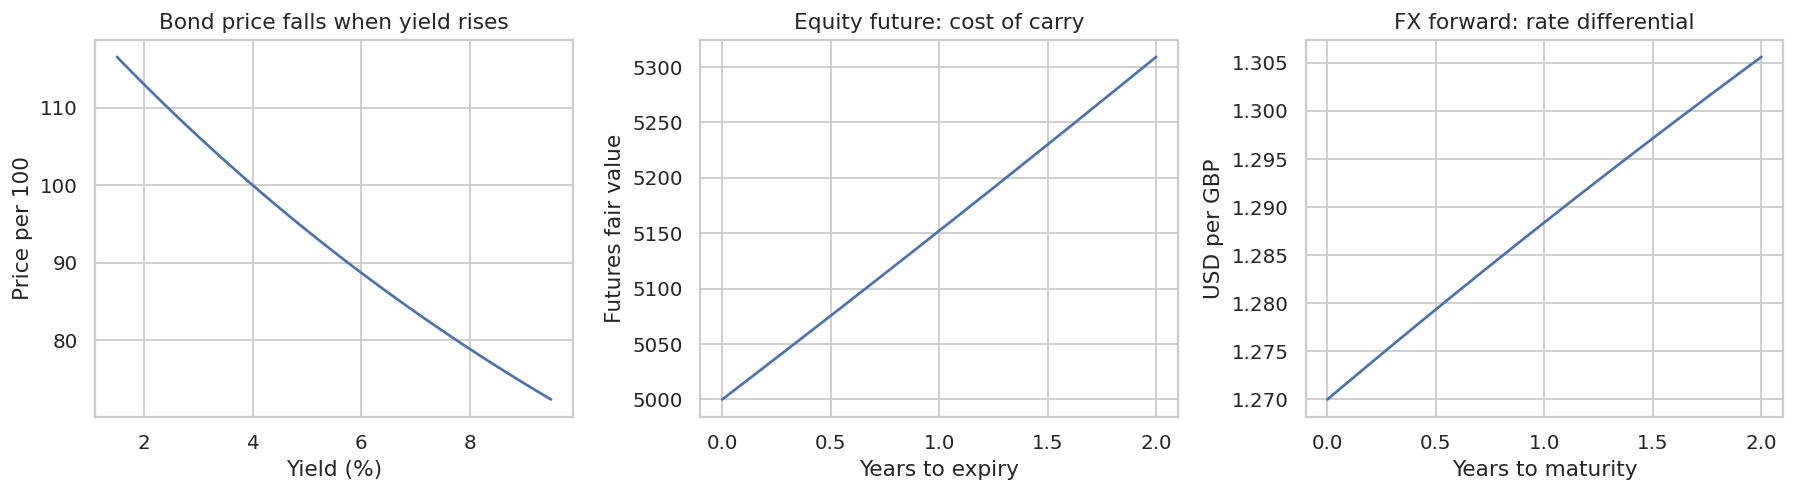

In [6]:
y_grid = np.linspace(.015,.095,100)
fig, ax = plt.subplots(1,3,figsize=(14,4))
ax[0].plot(y_grid*100,[bond_price_100(.04,y,7) for y in y_grid]); ax[0].set(xlabel='Yield (%)',ylabel='Price per 100',title='Bond price falls when yield rises')
tenors = np.linspace(0,2,100)
ax[1].plot(tenors,[future_fair(5000,.05,.02,t) for t in tenors]); ax[1].set(xlabel='Years to expiry',ylabel='Futures fair value',title='Equity future: cost of carry')
ax[2].plot(tenors,[fx_forward_fair(1.27,.035,.05,t) for t in tenors]); ax[2].set(xlabel='Years to maturity',ylabel='USD per GBP',title='FX forward: rate differential')
fig.tight_layout(); plt.show()

### Pricing drill (10 min)

- State the sign of bond DV01, explain why high-duration positions are rate-sensitive, and describe which curve should discount cash flows in a real pricing library.
- A 7-year 4% coupon bond trades at 96. How would you infer its yield? (Try a root solver.)
- Which conventions and market inputs would you request before pricing a *real* FX forward?

**Python technique:** decompose one instrument family per function, check invalid inputs, test monotonicity and no-arbitrage invariants.

## 3 — Build a multi-asset trade blotter

For each simulated fill, keep the instrument, side, fair price, paid execution price, cost, liquidity, market condition and client. We deliberately simulate imperfect fills: a positive pre-cost quote advantage can be wiped out by spread and slippage.

**Trade value in comparable units:**

\(\mathrm{execution\ edge}_{bp} = \mathrm{side}\times\frac{P_{fair}-P_{exec}}{P_{fair}}\times10,000\)

This is a *normalised teaching proxy* across product families, **not** the contractual cash-flow PV for every derivative. A production engine would use trade-specific payoffs, currencies, multipliers, settlement terms, discount curves and sensitivities.

In [7]:
instrument_spec = pd.DataFrame([
    ('GILT5','BOND','UK government bond', .037, 5.0, 0.0),
    ('CREDIT7','BOND','Investment-grade credit bond', .052, 7.0, 0.0),
    ('US_EQ','FUTURE','US equity index future', 0.0, .25, .015),
    ('UK_EQ','FUTURE','UK equity index future', 0.0, .50, .036),
    ('GBPUSD','FX','GBP/USD forward',0.0,.50,0.0),
    ('EURUSD','FX','EUR/USD forward',0.0,.25,0.0),
],columns=['instrument','asset_class','description','coupon','years','dividend_yield']).set_index('instrument')

def fair_value(instrument: str, mkt: pd.Series) -> float:
    '''Route pricing by instrument, with required-market-input checks in pricers.'''
    spec = instrument_spec.loc[instrument]
    if spec.asset_class == 'BOND':
        yld = mkt.gbp_rate + (mkt.credit_spread if instrument == 'CREDIT7' else 0)
        return bond_price_100(spec.coupon, yld, spec.years)
    if spec.asset_class == 'FUTURE':
        spot = mkt.us_equity_spot if instrument == 'US_EQ' else mkt.uk_equity_spot
        rate = mkt.usd_rate if instrument == 'US_EQ' else mkt.gbp_rate
        return future_fair(spot,rate,spec.dividend_yield,spec.years)
    spot = mkt.gbpusd if instrument == 'GBPUSD' else mkt.eurusd
    base_rate = mkt.gbp_rate if instrument == 'GBPUSD' else .034
    return fx_forward_fair(spot,base_rate,mkt.usd_rate,spec.years)

n_trades = 1_800
client_ids = clients.client_id.to_numpy()
client_approval = clients.set_index('client_id').approved_products.to_dict()
inst_names = instrument_spec.index.to_numpy()
records = []
for i in range(n_trades):
    day_idx = int(rng.integers(18, len(dates)-6))
    date = dates[day_idx]
    cid = str(rng.choice(client_ids))
    permitted = [x for x in inst_names if instrument_spec.loc[x,'asset_class'] in client_approval[cid]]
    instr = str(rng.choice(permitted))
    aclass = instrument_spec.loc[instr,'asset_class']
    side = int(rng.choice([-1,1]))
    usd_notional = float(rng.uniform(2e6,16e6))
    liquidity = float(np.clip(rng.beta(4,2),.08,1))
    fair = fair_value(instr,market.loc[date])
    quoted_edge = float(rng.normal(4.0 if aclass=='BOND' else 2.8,6.8))
    spread = 1.1 + 3.8*(1-liquidity) + (2.0 if aclass=='BOND' else 0)
    slippage = max(0.0, float(rng.normal(1.5 + 5*(1-liquidity) + .13*(usd_notional/1e6),1.9)))
    # Liquidity regime affects execution costs; client mandate is already respected.
    paid = fair * (1 + side * (spread + slippage - quoted_edge)/10_000)
    mom = float(market.equity_ret.iloc[max(day_idx-5,0):day_idx].sum()*10000)
    estimated_alpha = float(np.clip(.10 * side * mom + rng.normal(3,8),-35,35))
    future_alpha = float(.35*estimated_alpha + rng.normal(0,17))
    realized_net = future_alpha + side*(fair-paid)/fair*10000
    records.append((f'T{i+1:05}',date,cid,instr,aclass,side,usd_notional,liquidity,
                    fair,paid,spread,slippage,quoted_edge,estimated_alpha,
                    future_alpha,realized_net,day_idx))

trades = pd.DataFrame(records, columns=['trade_id','trade_date','client_id','instrument',
    'asset_class','side','usd_notional','liquidity_score','fair_price','execution_price',
    'spread_cost_bps','slippage_bps','quoted_edge_bps','estimated_alpha_bps',
    'future_alpha_bps','realized_net_bps','day_idx'])
trades['execution_edge_bps'] = trades.side * (trades.fair_price-trades.execution_price)/trades.fair_price*10000
trades['expected_net_bps'] = trades.estimated_alpha_bps + trades.execution_edge_bps
trades['expected_net_usd'] = trades.usd_notional*trades.expected_net_bps/10000
trades['realized_net_usd'] = trades.usd_notional*trades.realized_net_bps/10000
trades['trade_month'] = trades.trade_date.dt.to_period('M').astype(str)
trades = trades.sort_values(['trade_date','trade_id']).reset_index(drop=True)
display(trades[['trade_id','trade_date','client_id','instrument','side','usd_notional',
                'fair_price','execution_price','execution_edge_bps','expected_net_usd']].head())
print('Rows:',len(trades),'| distinct clients:',trades.client_id.nunique())

Rows: 1800 | distinct clients: 8


,trade_id,trade_date,client_id,instrument,side,usd_notional,fair_price,execution_price,execution_edge_bps,expected_net_usd
0,T00063,2025-01-28,C004,UK_EQ,-1,"5,497,565.2293","7,057.0270","7,058.7683",2.4675,"18,965.7136"
1,T00731,2025-01-28,C002,CREDIT7,1,"4,267,029.7135",100.3294,100.4508,-12.0926,"-18,956.0610"
2,T00232,2025-01-29,C005,EURUSD,1,"5,308,061.4212",1.1058,1.1060,-2.2533,"-15,899.2929"
3,T00318,2025-01-29,C004,GILT5,-1,"7,763,020.4364",98.9390,98.8977,-4.1655,"11,032.7008"
4,T00387,2025-01-29,C005,EURUSD,-1,"9,987,532.2056",1.1058,1.1045,-11.8297,"-5,123.7524"


### Data-quality contract and unit checks

Real financial pipelines fail on stale quotes, duplicate identifiers, missing product masters, inconsistent currencies and bad timestamps. Catch these before modelling.

In [8]:
def validate_blotter(df: pd.DataFrame) -> dict[str,int]:
    required = ['trade_id','trade_date','client_id','instrument','side',
                'usd_notional','fair_price','execution_price','liquidity_score']
    missing = {x: int(df[x].isna().sum()) for x in required}
    return {
        'duplicate_id': int(df.trade_id.duplicated().sum()),
        'missing_fields': sum(missing.values()),
        'bad_side': int((~df.side.isin([-1,1])).sum()),
        'bad_notional': int((df.usd_notional <= 0).sum()),
        'bad_price': int(((df.fair_price <= 0)|(df.execution_price <= 0)).sum()),
        'unknown_instrument': int((~df.instrument.isin(instrument_spec.index)).sum()),
        'invalid_liquidity': int(((df.liquidity_score<0)|(df.liquidity_score>1)).sum()),
    }

dirty = pd.concat([trades, trades.iloc[[3]]],ignore_index=True)
dirty.loc[10,'liquidity_score'] = np.nan
print('Intentionally dirty example:',validate_blotter(dirty))
print('Clean portfolio:',validate_blotter(trades))
assert all(v == 0 for v in validate_blotter(trades).values())
assert np.allclose(trades.execution_edge_bps,
                   trades.quoted_edge_bps-trades.spread_cost_bps-trades.slippage_bps)

Intentionally dirty example: {'duplicate_id': 1, 'missing_fields': 1, 'bad_side': 0, 'bad_notional': 0, 'bad_price': 0, 'unknown_instrument': 0, 'invalid_liquidity': 0}
Clean portfolio: {'duplicate_id': 0, 'missing_fields': 0, 'bad_side': 0, 'bad_notional': 0, 'bad_price': 0, 'unknown_instrument': 0, 'invalid_liquidity': 0}


## 4 — Data analysis: what makes a trade attractive or problematic?

Start with **simple transparent baselines**. Use `groupby`, explicit weights, distribution plots and time-aware slices. Averages can be misleading when notional sizes differ greatly.

Avoid treating `future_alpha_bps` or `realized_net_bps` as a **live recommendation input**; they are retrospective outcomes. In this notebook we reserve them for evaluation.

In [9]:
def weighted_mean(values: pd.Series, weights: pd.Series) -> float:
    if len(values) != len(weights) or len(values)==0 or (weights < 0).any() or weights.sum() <= 0:
        raise ValueError('incompatible values or weights')
    return float(np.average(values, weights=weights))

asset_summary = trades.groupby('asset_class').apply(
    lambda g: pd.Series({'trades':len(g), 'notional_usd':g.usd_notional.sum(),
        'avg_slippage_bps':g.slippage_bps.mean(),
        'notional_weighted_edge_bps':weighted_mean(g.execution_edge_bps,g.usd_notional),
        'positive_expected_share':(g.expected_net_bps > 0).mean()}),
    include_groups=False).sort_values('notional_usd',ascending=False)
display(asset_summary)

,trades,notional_usd,avg_slippage_bps,notional_weighted_edge_bps,positive_expected_share
asset_class,,,,,
FX,782.0000,"7,135,593,440.1662",4.3376,-4.1339,0.5090
BOND,596.0000,"5,455,933,395.0951",4.4341,-5.1406,0.4497
FUTURE,422.0000,"3,836,393,797.4957",4.3012,-3.7596,0.4787


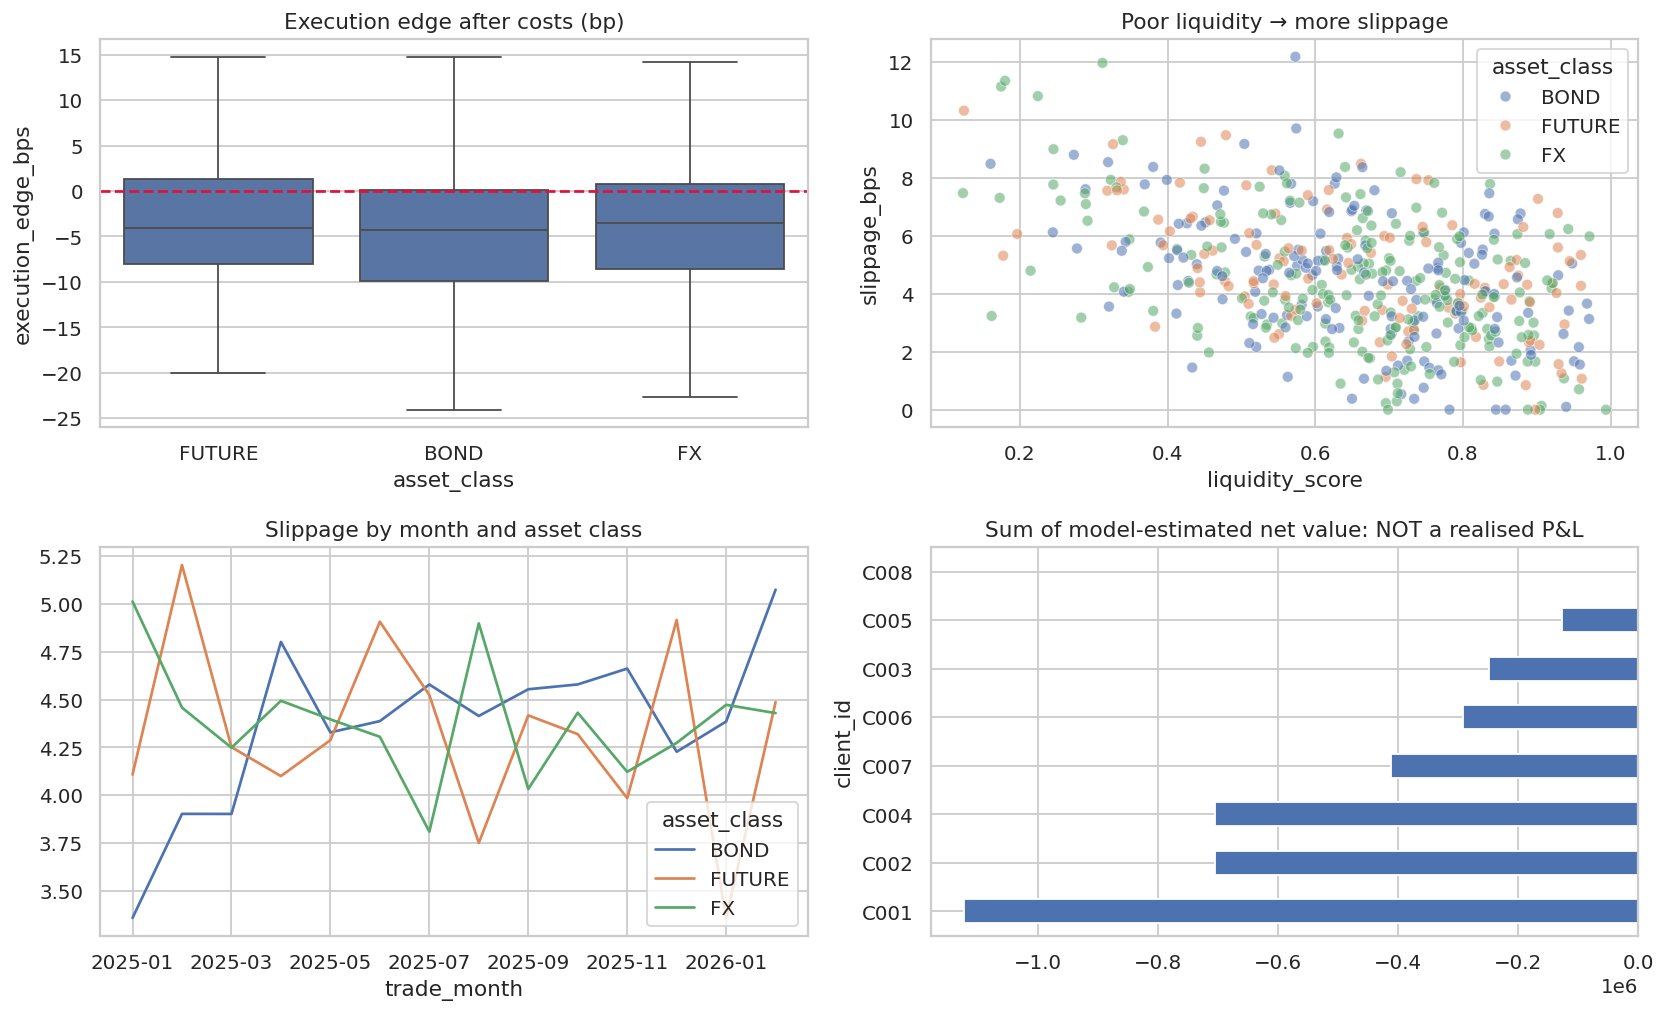

In [10]:
fig, ax = plt.subplots(2,2,figsize=(13,8))
sns.boxplot(data=trades,x='asset_class',y='execution_edge_bps',ax=ax[0,0],showfliers=False)
ax[0,0].axhline(0,color='crimson',linestyle='--');ax[0,0].set_title('Execution edge after costs (bp)')
sns.scatterplot(data=trades.sample(500,random_state=42),x='liquidity_score',y='slippage_bps',
                hue='asset_class',alpha=.55,ax=ax[0,1]);ax[0,1].set_title('Poor liquidity → more slippage')
trades.groupby(['trade_month','asset_class']).slippage_bps.mean().unstack().plot(ax=ax[1,0],title='Slippage by month and asset class')
trades.groupby('client_id').expected_net_usd.sum().sort_values().plot(kind='barh',ax=ax[1,1],title='Sum of model-estimated net value: NOT a realised P&L')
fig.tight_layout();plt.show()

In [11]:
top_problematic = (trades.assign(cost_usd=(trades.spread_cost_bps+trades.slippage_bps)*trades.usd_notional/10000)
                  .nlargest(8,'cost_usd'))
display(top_problematic[['trade_id','client_id','instrument','usd_notional',
                         'liquidity_score','spread_cost_bps','slippage_bps','cost_usd']])
print('Correlation is diagnostic rather than causation:',
      round(trades[['liquidity_score','slippage_bps']].corr().iloc[0,1],3))

Correlation is diagnostic rather than causation: -0.399


,trade_id,client_id,instrument,usd_notional,liquidity_score,spread_cost_bps,slippage_bps,cost_usd
342,T00398,C005,EURUSD,"15,559,767.3526",0.1799,4.2162,11.3508,"24,221.9235"
1249,T01666,C002,GILT5,"13,770,676.4348",0.5731,4.7222,12.1818,"23,277.9647"
862,T01146,C006,CREDIT7,"14,886,319.3843",0.3212,5.6793,9.5996,"22,744.6726"
1171,T00366,C008,CREDIT7,"15,894,421.9369",0.2375,5.9974,8.1583,"22,499.6221"
1622,T00847,C008,EURUSD,"15,391,117.1944",0.3943,3.4016,11.1290,"22,364.2056"
1424,T01634,C004,UK_EQ,"14,929,999.8295",0.1243,4.4277,10.3207,"22,019.3634"
698,T01308,C003,GILT5,"13,110,262.4970",0.3142,5.7060,10.9193,"21,796.1989"
599,T00514,C004,GILT5,"14,680,195.2288",0.2731,5.8622,8.7978,"21,521.1598"


### Python exercise A (15 min) — group, join, rank

1. Merge client objective and VaR limit into the blotter (`merge(..., validate='many_to_one')`).
2. Calculate each client's notional-weighted execution edge. Why not just use `.mean()`?
3. For each client, find the three fills with the worst execution cost in USD (hint: `sort_values`, `groupby().head(3)`).
4. Identify trades where `estimated_alpha_bps > 0` but `expected_net_bps < 0`.

Try it here, then consult the solution in Module 8.

In [12]:
# EXERCISE A — write your implementation. Keep the notebook runnable while unfinished.
# enriched = trades.merge(..., validate='many_to_one')
# client_weighted_edge = ...
# worst_three_each = ...
# cost_overwhelms_signal = ...

## 5 — Portfolio factor risk and client-specific suitability

**Why not recommend purely on predicted return?** A good standalone trade can increase a client's concentrated exposure, breach an approved-product list or worsen a stress scenario.

We use a simple *linear factor P&L approximation*:

\(\mathrm{P\&L}_t \approx \boldsymbol{e}^{\mathsf T}\boldsymbol{f}_t\)

where factor vector is `[equity return, yield change in bp, GBP/USD return, credit-spread change in bp]`, and exposure is **USD P&L per one unit of each factor**. Bond rate exposure uses `−notional × modified duration / 10000` USD/bp. This approximation excludes convexity, nonlinear options, instrument basis and second-order effects.

Risk vocabulary:

- **VaR (99%, one day):** a loss threshold, *not* a worst-case loss.
- **Expected shortfall:** average loss beyond the VaR threshold, a tail-focused measure.
- **Stress test:** revalue or approximate P&L under an explicitly chosen severe scenario.
- **Incremental VaR:** portfolio VaR after the trade minus VaR before it. It can be negative when a trade hedges existing exposure.

In [13]:
FACTOR_COLS = ['equity_ret','rates_bp','fx_ret','credit_bp']
factor_history = market[FACTOR_COLS]

def factor_exposure(instrument: str, signed_notional: float, mkt: pd.Series) -> np.ndarray:
    '''USD P&L per factor-unit; simplified local-linear Greeks.'''
    if instrument in ['US_EQ','UK_EQ']:
        return np.array([signed_notional*(1.0 if instrument=='US_EQ' else .75),0,0,0])
    if instrument in ['GBPUSD','EURUSD']:
        return np.array([0,0,signed_notional*(1.0 if instrument=='GBPUSD' else .72),0])
    spec = instrument_spec.loc[instrument]
    yld = mkt.gbp_rate + (mkt.credit_spread if instrument=='CREDIT7' else 0)
    duration = bond_modified_duration(spec.coupon,yld,spec.years)
    rate_dv01 = -signed_notional*duration/10_000
    credit_dv01 = rate_dv01 if instrument=='CREDIT7' else 0.0
    return np.array([0,rate_dv01,0,credit_dv01])

position_rows = []
for cid in clients.client_id:
    permitted = [x for x in inst_names if instrument_spec.loc[x,'asset_class'] in client_approval[cid]]
    for j in range(5):
        instr = str(rng.choice(permitted))
        position_rows.append((cid,instr,int(rng.choice([-1,1]))*float(rng.uniform(6e6,22e6))))
positions = pd.DataFrame(position_rows,columns=['client_id','instrument','signed_notional'])
asof_market = market.iloc[-1]

def portfolio_exposure(client_id: str) -> np.ndarray:
    book = positions.loc[positions.client_id==client_id]
    return np.sum([factor_exposure(p.instrument,p.signed_notional,asof_market)
                   for p in book.itertuples()],axis=0)

def historical_var_es(exposure: np.ndarray, level: float=.99) -> tuple[float,float]:
    '''Historical simulation: positive USD loss is bad; no mean-shift assumption.'''
    pnl = factor_history.to_numpy() @ exposure
    losses = -pnl
    var = float(np.quantile(losses,level))
    es = float(losses[losses>=var].mean())
    return max(var,0.0),es

def parametric_var(exposure: np.ndarray, level: float=.99) -> float:
    '''Zero-mean Gaussian VaR, for a baseline only (tail/normality caveats).'''
    cov = np.cov(factor_history.to_numpy(),rowvar=False)
    return float(norm.ppf(level)*np.sqrt(exposure @ cov @ exposure))

risk_rows=[]
for cid in clients.client_id:
    e=portfolio_exposure(cid)
    hvar,es=historical_var_es(e)
    risk_rows.append((cid,hvar,es,parametric_var(e),
                      positions.loc[positions.client_id==cid,'signed_notional'].abs().sum()))
risk_report=pd.DataFrame(risk_rows,columns=['client_id','hist_var_99','hist_es_99',
                      'gaussian_var_99','gross_usd']).merge(clients,on='client_id')
risk_report['var_limit_utilisation']=risk_report.hist_var_99/risk_report.var_limit_usd
display(risk_report[['client_name','gross_usd','hist_var_99','hist_es_99',
                     'gaussian_var_99','var_limit_usd','var_limit_utilisation']])

,client_name,gross_usd,hist_var_99,hist_es_99,gaussian_var_99,var_limit_usd,var_limit_utilisation
0,Pension Scheme,"73,979,832.1756","437,569.2931","501,043.0495","487,784.7773","3,400,000.0000",0.1287
1,Macro Fund,"85,096,066.4800","847,405.9487","1,101,465.7530","832,341.9606","5,500,000.0000",0.1541
2,Insurance Group,"67,279,116.4909","327,627.0225","432,543.4243","316,151.5048","3,200,000.0000",0.1024
3,Endowment,"92,285,416.1379","888,028.3367","1,000,221.6860","939,269.5154","4,000,000.0000",0.2220
4,Asset Manager,"79,032,246.8562","923,924.1631","1,008,028.6863","938,052.3114","3,500,000.0000",0.2640
5,Corporate Treasury,"75,127,913.1147","271,405.0531","361,733.8027","295,386.8385","2,400,000.0000",0.1131
6,Sovereign Investor,"82,779,127.2660","616,426.6746","762,061.1573","600,565.3981","7,000,000.0000",0.0881
7,Family Office,"73,923,353.0724","511,657.6567","620,612.1747","519,484.3248","2,800,000.0000",0.1827


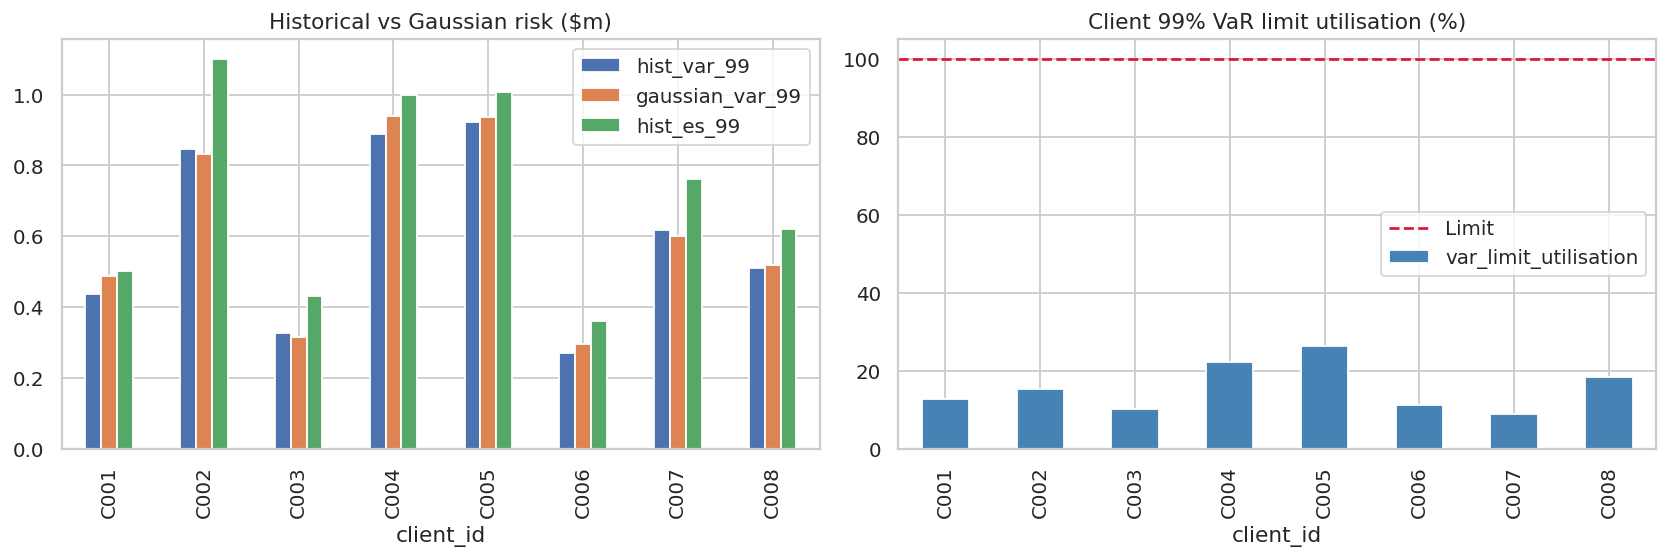

In [14]:
fig, axes=plt.subplots(1,2,figsize=(13,4.5))
risk_report.set_index('client_id')[['hist_var_99','gaussian_var_99','hist_es_99']].div(1e6).plot(kind='bar',ax=axes[0],title='Historical vs Gaussian risk ($m)')
risk_report.set_index('client_id').var_limit_utilisation.mul(100).plot(kind='bar',ax=axes[1],color='steelblue',title='Client 99% VaR limit utilisation (%)')
axes[1].axhline(100,color='crimson',linestyle='--',label='Limit');axes[1].legend()
fig.tight_layout();plt.show()

,C001,C002,C003,C004,C005,C006,C007,C008
scenario,,,,,,,,
Risk-off,2.1500,0.9900,0.5100,2.1000,2.1100,0.6900,0.0300,0.3700
Rates spike,1.2800,0.8800,0.9300,0.7300,0.4900,0.2800,1.0300,-0.8700
FX dislocation,3.2300,4.8400,-0.8600,0.7400,-0.2800,1.9400,-0.4300,0.1100
Relief rally,-1.4900,-0.6300,-0.3500,-1.7800,-1.7200,-0.5000,0.1300,-0.3300


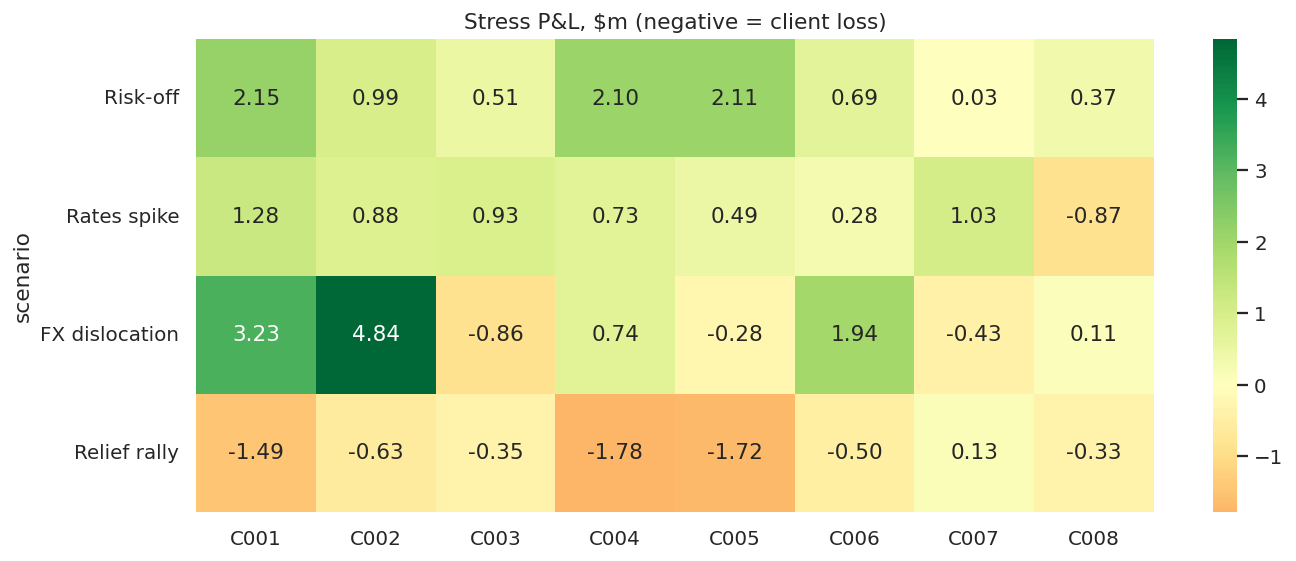

In [15]:
stress = pd.DataFrame([
    ('Risk-off',-.075,25,-.035,55),
    ('Rates spike',-.020,60,-.015,20),
    ('FX dislocation',-.025,10,-.095,15),
    ('Relief rally',.060,-20,.025,-35),
],columns=['scenario']+FACTOR_COLS).set_index('scenario')
client_stress = pd.DataFrame({cid:stress.to_numpy() @ portfolio_exposure(cid)
                              for cid in clients.client_id},index=stress.index)/1e6
display(client_stress.round(2))
fig,ax=plt.subplots(figsize=(11,4.5))
sns.heatmap(client_stress,center=0,cmap='RdYlGn',annot=True,fmt='.2f',ax=ax)
ax.set_title('Stress P&L, $m (negative = client loss)');plt.tight_layout();plt.show()

### Compare candidate trades for a specific client

Recommend only from the customer's approved universe and *compare before/after portfolio risk*. Here, expected alpha is a hypothetical pre-trade estimate, not foresight. We explicitly screen product permissions, a gross exposure ceiling, a risk limit and a simple product concentration limit.

In [16]:
def rank_candidates(client_id: str, candidate_notional: float=6e6) -> pd.DataFrame:
    cl=clients.set_index('client_id').loc[client_id]
    before=portfolio_exposure(client_id)
    var_before=historical_var_es(before)[0]
    held=positions.loc[positions.client_id==client_id]
    base_gross=held.signed_notional.abs().sum()
    rows=[]
    for instr,spec in instrument_spec.iterrows():
        # The optimal trading direction is a *research hypothesis*, never known future return.
        assumed_alpha = {'GILT5':8,'CREDIT7':12,'US_EQ':13,'UK_EQ':7,'GBPUSD':9,'EURUSD':5}[instr]
        side = {'GILT5':1,'CREDIT7':1,'US_EQ':1,'UK_EQ':-1,'GBPUSD':-1,'EURUSD':1}[instr]
        expected_cost = {'BOND':6.5,'FUTURE':4.0,'FX':3.4}[spec.asset_class]
        after=before+factor_exposure(instr,side*candidate_notional,asof_market)
        var_after=historical_var_es(after)[0]
        class_gross=held.loc[held.instrument.map(instrument_spec.asset_class)==spec.asset_class,
                             'signed_notional'].abs().sum()
        future_share=(class_gross+candidate_notional)/(base_gross+candidate_notional)
        allowed=spec.asset_class in cl.approved_products
        gross_ok=base_gross+candidate_notional<=cl.gross_limit_usd
        var_ok=var_after<=cl.var_limit_usd
        concentration_ok=future_share<=cl.single_product_max_share
        suitable=allowed and gross_ok and var_ok and concentration_ok
        net_alpha=assumed_alpha-expected_cost
        # Illustrative risk-adjusted *screening score*, not a calibrated economic utility.
        incr_var=var_after-var_before
        score_usd=candidate_notional*net_alpha/10000 - .015*max(incr_var,0)
        rows.append((instr,spec.asset_class,side,assumed_alpha,expected_cost,net_alpha,
                     incr_var,var_after,future_share,allowed,gross_ok,var_ok,
                     concentration_ok,suitable,score_usd))
    cols=['instrument','asset_class','side','expected_alpha_bps','expected_cost_bps',
          'net_alpha_bps','incremental_var_usd','post_var_usd','asset_class_gross_share',
          'approved','gross_ok','var_ok','concentration_ok','suitable','screening_score_usd']
    return pd.DataFrame(rows,columns=cols).sort_values('screening_score_usd',ascending=False)

candidate_table=rank_candidates('C001')
display(candidate_table[['instrument','side','net_alpha_bps','incremental_var_usd',
                         'asset_class_gross_share','approved','var_ok','concentration_ok',
                         'suitable','screening_score_usd']])
print('Eligible candidates:',candidate_table.suitable.sum())

Eligible candidates: 2


,instrument,side,net_alpha_bps,incremental_var_usd,asset_class_gross_share,approved,var_ok,concentration_ok,suitable,screening_score_usd
2,US_EQ,1,9.0000,"33,743.1213",0.0750,False,True,True,False,"4,893.8532"
1,CREDIT7,1,5.5000,"-15,354.8242",0.6176,True,True,False,False,"3,300.0000"
4,GBPUSD,-1,5.6000,"82,096.0863",0.4574,True,True,True,True,"2,128.5587"
5,EURUSD,1,1.6000,"-46,005.6687",0.4574,True,True,True,True,960.0000
0,GILT5,1,1.5000,"-10,306.7640",0.6176,True,True,False,False,900.0000
3,UK_EQ,-1,3.0000,"67,866.8995",0.0750,False,True,True,False,781.9965


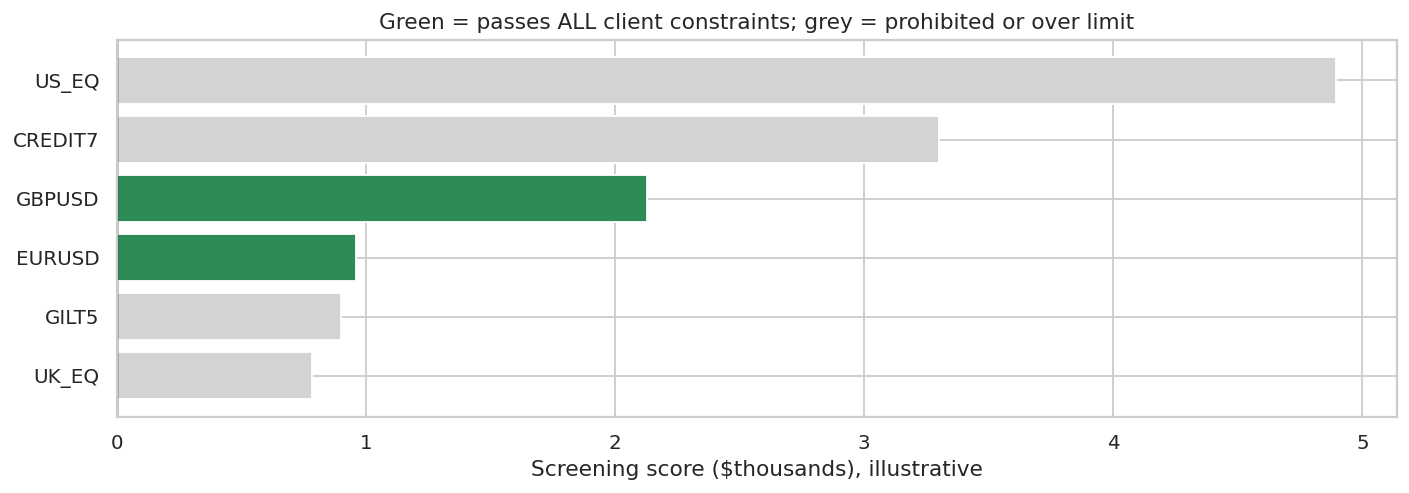

In [17]:
fig,ax=plt.subplots(figsize=(11,4))
ordered=candidate_table.sort_values('screening_score_usd')
ax.barh(ordered.instrument,ordered.screening_score_usd/1000,
        color=np.where(ordered.suitable,'seagreen','lightgray'))
ax.axvline(0,color='black',linewidth=.8)
ax.set(xlabel='Screening score ($thousands), illustrative',title='Green = passes ALL client constraints; grey = prohibited or over limit')
plt.tight_layout();plt.show()

**Interview question:** Why might the highest-scoring trade still be unsuitable? Discuss client mandate, concentration, executable liquidity, settlement conventions, collateral, bilateral credit exposure, model uncertainty, timing of quotes and trader overrides. Explain that a rejection reason should be captured as structured metadata for a human reviewer.

### Python exercise B (20 min) — marginal risk and constraints

1. Write a function that returns `incremental_var_usd` for any `client_id`, instrument, side and notional.
2. Demonstrate a candidate with **negative** incremental VaR (i.e. risk-reducing), if one exists for some client/side.
3. Replace the illustrative 1.5% risk penalty with a **user-specified** risk-aversion parameter. How does ranking change?
4. What would you cache in a low-latency quote path, and what must be recomputed after positions change?

In [18]:
# EXERCISE B — write/test your own solution.
# def incremental_var(client_id, instrument, side, notional):
#     ...

## 6 — Predict trades that need review (machine learning)

**Business framing:** Flag trades likely to have materially poor subsequent outcomes, or unusually poor fill quality, for prioritised *human review*. This is not a prediction of client suitability. The synthetic outcome is generated with noise and partly depends on information available only **after** the trade.

**Critical anti-leakage rule:** Features are measured **at decision time**. `future_alpha_bps`, `realized_net_bps`, `realized_net_usd` and `needs_review` are never input features. We split chronologically to mimic deployment and compare against an honest dummy baseline.

For review triage, **precision** controls false alerts and analyst workload; **recall** controls missed problematic trades. Class imbalance makes accuracy alone misleading.

In [19]:
# Retrospective synthetic target, assembled only after outcome was observable.
trades['needs_review'] = ((trades.realized_net_bps < -21) |
                           (trades.slippage_bps > 11)).astype(int)
# Avoid client identifiers as a shortcut to memorising profiles in a tiny sample.
features=['asset_class','instrument','side','usd_notional','liquidity_score',
          'spread_cost_bps','slippage_bps','quoted_edge_bps',
          'estimated_alpha_bps','execution_edge_bps']
cutoff=trades.trade_date.quantile(.75)
train=trades.loc[trades.trade_date<=cutoff].copy()
test=trades.loc[trades.trade_date>cutoff].copy()
assert train.trade_date.max() < test.trade_date.min()
assert set(features).isdisjoint({'future_alpha_bps','realized_net_bps','needs_review','realized_net_usd'})
print('Train:',len(train),'Test:',len(test),'Cutoff:',cutoff.date())
print('Target prevalence train/test:',round(train.needs_review.mean(),3),round(test.needs_review.mean(),3))

numeric=[c for c in features if c not in ['asset_class','instrument']]
categorical=['asset_class','instrument']
preprocess=ColumnTransformer([
    ('num',Pipeline([('impute',SimpleImputer(strategy='median')),
                    ('scale',StandardScaler())]),numeric),
    ('cat',OneHotEncoder(handle_unknown='ignore'),categorical)])
models={
    'Dummy':DummyClassifier(strategy='prior'),
    'Logistic':Pipeline([('pre',preprocess),('clf',LogisticRegression(max_iter=1000,
                                                        class_weight='balanced',random_state=SEED))]),
    'Random forest':Pipeline([('pre',preprocess),('clf',RandomForestClassifier(
                        n_estimators=160,min_samples_leaf=10,max_depth=7,
                        class_weight='balanced',random_state=SEED,n_jobs=-1))])}

predictions={}
metrics=[]
for name,model in models.items():
    model.fit(train[features],train.needs_review)
    proba=model.predict_proba(test[features])[:,1]
    predictions[name]=proba
    metrics.append((name,average_precision_score(test.needs_review,proba),
                    roc_auc_score(test.needs_review,proba),
                    brier_score_loss(test.needs_review,proba)))
ml_report=pd.DataFrame(metrics,columns=['model','average_precision','roc_auc','brier_lower_is_better'])
display(ml_report.sort_values('average_precision',ascending=False))

Train: 1351 Test: 449 Cutoff: 2025-11-11
Target prevalence train/test: 0.185 0.229


,model,average_precision,roc_auc,brier_lower_is_better
1,Logistic,0.5435,0.7911,0.1909
2,Random forest,0.5239,0.7721,0.1668
0,Dummy,0.2294,0.5000,0.1787


              precision    recall  f1-score   support

           0       0.92      0.56      0.70       346
           1       0.36      0.83      0.51       103

    accuracy                           0.63       449
   macro avg       0.64      0.70      0.60       449
weighted avg       0.79      0.63      0.65       449



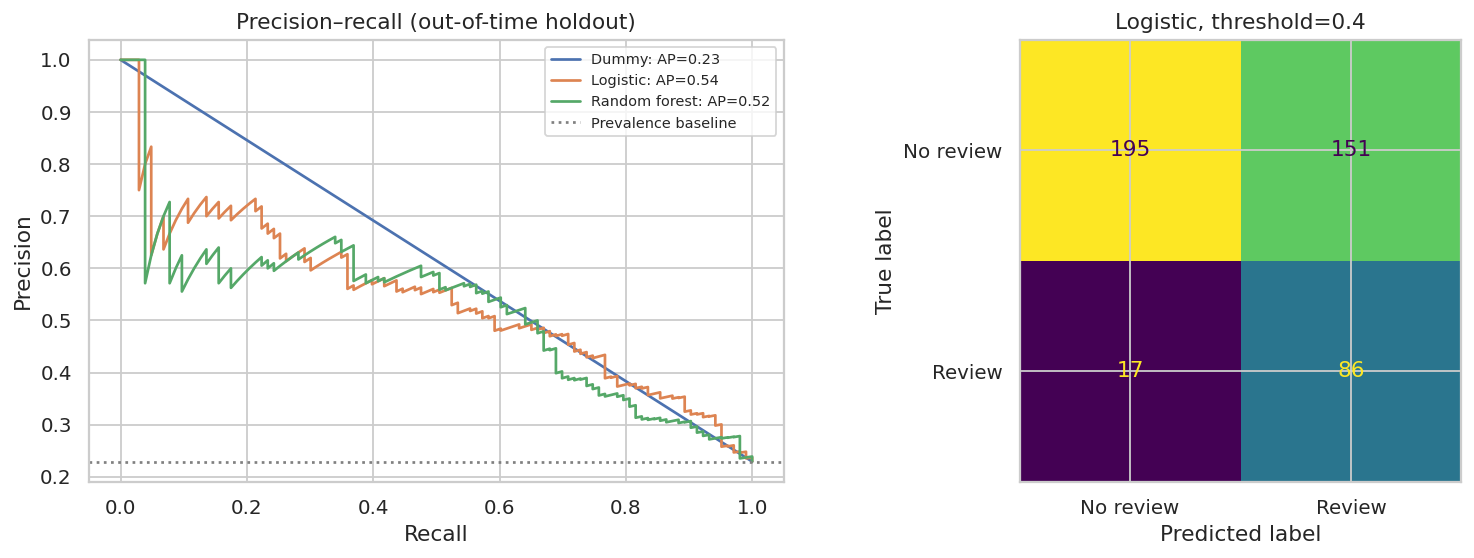

In [20]:
fig,axs=plt.subplots(1,2,figsize=(12.5,4.5))
base_rate=test.needs_review.mean()
for name,proba in predictions.items():
    p,r,_=precision_recall_curve(test.needs_review,proba)
    axs[0].plot(r,p,label=f'{name}: AP={average_precision_score(test.needs_review,proba):.2f}')
axs[0].axhline(base_rate,color='gray',linestyle=':',label='Prevalence baseline')
axs[0].set(xlabel='Recall',ylabel='Precision',title='Precision–recall (out-of-time holdout)');axs[0].legend(fontsize=8)
chosen='Logistic';threshold=.40
pred=(predictions[chosen]>=threshold).astype(int)
ConfusionMatrixDisplay.from_predictions(test.needs_review,pred,display_labels=['No review','Review'],
                                        colorbar=False,ax=axs[1]);axs[1].set_title(f'{chosen}, threshold={threshold}')
fig.tight_layout();plt.show()
print(classification_report(test.needs_review,pred,zero_division=0))

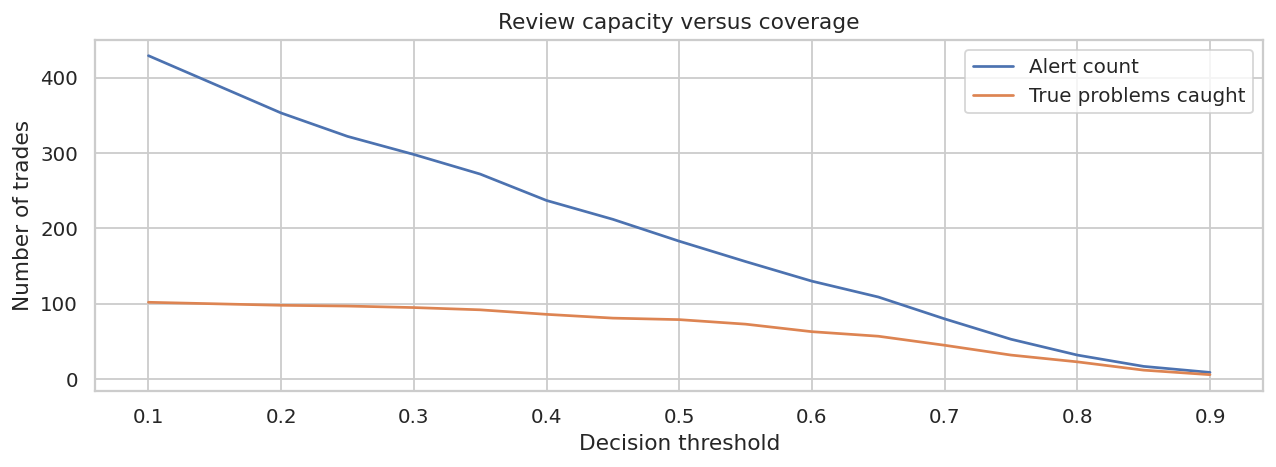

,threshold,alerts,captured_true_problems,precision
0,0.1000,429,102,0.2378
3,0.2500,322,97,0.3012
6,0.4000,237,86,0.3629
9,0.5500,156,73,0.4679
12,0.7000,80,45,0.5625
15,0.8500,17,12,0.7059


In [21]:
# Operational threshold curve: how many alerts must a reviewer handle?
thresholds=np.arange(.1,.91,.05)
threshold_report=pd.DataFrame([{'threshold':t,
    'alerts':int((predictions['Logistic']>=t).sum()),
    'captured_true_problems':int(((predictions['Logistic']>=t)&(test.needs_review.to_numpy()==1)).sum()),
    'precision':float(test.needs_review.to_numpy()[predictions['Logistic']>=t].mean()) if (predictions['Logistic']>=t).any() else np.nan}
    for t in thresholds])
fig,ax=plt.subplots(figsize=(10,3.8))
ax.plot(threshold_report.threshold,threshold_report.alerts,label='Alert count')
ax.plot(threshold_report.threshold,threshold_report.captured_true_problems,label='True problems caught')
ax.set(xlabel='Decision threshold',ylabel='Number of trades',title='Review capacity versus coverage');ax.legend()
plt.tight_layout();plt.show()
display(threshold_report.iloc[::3])

### Model limitations and interview follow-ups

- A lower test-period base rate after a market regime change can alter precision even if ranking remains useful.
- A high PR-AUC on **synthetic labels** is not evidence of a profitable trading strategy.
- Calibrate probabilities and align threshold to review capacity/costs; validate by client segment, instrument and time.
- Never randomly split rows if the same time-series events create correlated outcomes or overlapping forward horizons. Consider purged/embargoed walk-forward validation for overlapping labels.
- Operational escalation decisions need explainability, an override trail and sampling of false negatives.

### Python exercise C (20 min) — feature leakage and thresholding

1. Create a `Pipeline` with median imputation, scaling and logistic regression yourself.
2. Change threshold to allow **at most 20 review alerts** on the test set; find the largest-recall threshold satisfying the capacity.
3. Add a 5-day trailing *past-only* rolling volatility feature, using a correctly timestamped join from `market`.
4. Explain what happens if you leak `realized_net_bps` into the feature list.

In [22]:
# EXERCISE C — code here. Do not add future outcome columns to input features.

## 7 — Hedge a bond portfolio with bond futures (DV01 matching)

**Case:** Client holds $30m of rate-sensitive bonds with modified duration 6; hedge with a government bond future with $100,000 notional per contract and effective duration 7. Ignore CTD/conversion factors, repo specialness and futures-bond basis for now.

\(\mathrm{DV01}_{bond} = N\times D\times 10^{-4}\)

\(n_{futures} \approx \frac{N_{bond}D_{bond}}{N_{contract}D_{future}}\)

Short approximately `n` futures contracts to offset the **interest-rate** risk of a long bond position. Credit-spread exposure is not hedged by a government-bond future. In a real desk, account for CTD, conversion factor, BPV, curve-key-rate buckets, spread risk and basis.

Bond DV01 $18,000/bp | Future DV01 $70/bp/contract
SHORT 257 contracts | Hedge DV01 $17,990/bp
Additional loss from +30bp credit spread (if duration~6): $-540,000


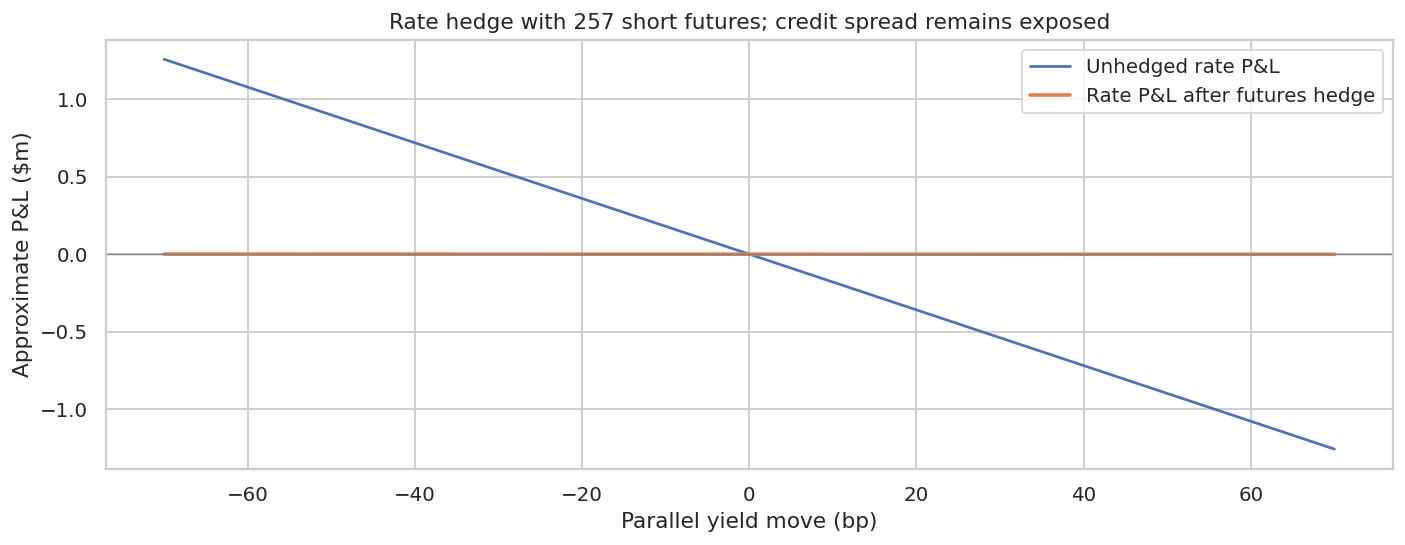

In [23]:
bond_notional=30e6
bond_duration=6.0
future_contract_notional=100_000
future_duration=7.0
bond_dv01=bond_notional*bond_duration/10_000
future_dv01=future_contract_notional*future_duration/10_000
contracts=round(bond_dv01/future_dv01)
effective_future_dv01=contracts*future_dv01
print(f'Bond DV01 ${bond_dv01:,.0f}/bp | Future DV01 ${future_dv01:,.0f}/bp/contract')
print(f'SHORT {contracts} contracts | Hedge DV01 ${effective_future_dv01:,.0f}/bp')

yield_changes=np.linspace(-70,70,141)
credit_shock=30  # +30bp credit spread widening is NOT offset by rate futures
unhedged_rate=-bond_dv01*yield_changes
hedged_rate=(-bond_dv01+effective_future_dv01)*yield_changes
fig,ax=plt.subplots(figsize=(11,4.4))
ax.plot(yield_changes,unhedged_rate/1e6,label='Unhedged rate P&L')
ax.plot(yield_changes,hedged_rate/1e6,label='Rate P&L after futures hedge',linewidth=2)
ax.axhline(0,color='gray',linewidth=.8)
ax.set(xlabel='Parallel yield move (bp)',ylabel='Approximate P&L ($m)',
       title=f'Rate hedge with {contracts} short futures; credit spread remains exposed')
ax.legend();plt.tight_layout();plt.show()
print(f'Additional loss from +30bp credit spread (if duration~6): ${-bond_dv01*credit_shock:,.0f}')
assert abs(bond_dv01-effective_future_dv01) <= future_dv01/2

**Interview challenge:** Does a hedge ratio based on regression of historical P&L match a duration hedge? Not necessarily. The former minimises historical variance under stable relationships; the latter matches local rate sensitivity. Explain **basis risk**, changing betas and stress conditions.

### Python exercise D (15 min) — regression hedge ratio

Generate synthetic daily bond-portfolio P&L and futures P&L from `factor_history`. Fit \(h=\operatorname{Cov}(P_b,P_f)/\operatorname{Var}(P_f)\) and compare it with the DV01-based ratio. Be explicit about whether `P_f` denotes the P&L of a **long** future, and whether the hedge takes `-h` units.

In [24]:
# EXERCISE D — optional coding practice.

## 8 — Operational monitoring, review and production design

Even excellent research results can fail if market snapshots are stale, positions are outdated or recommendations are not reproducible. Start with a small, observable system.

Triggered dates: 6 out of 300


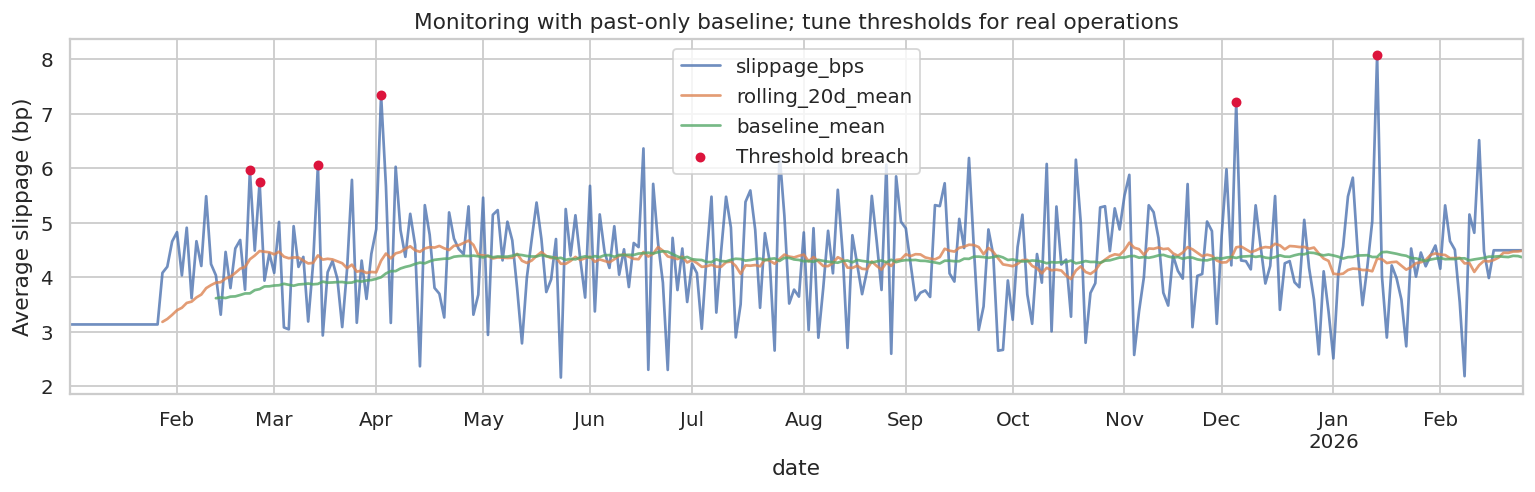

In [25]:
daily_slippage=(trades.groupby('trade_date').slippage_bps.mean()
                .reindex(dates).interpolate(limit_direction='both'))
monitor=pd.DataFrame({'slippage_bps':daily_slippage})
monitor['rolling_20d_mean']=monitor.slippage_bps.rolling(20,min_periods=20).mean()
monitor['rolling_20d_std']=monitor.slippage_bps.rolling(20,min_periods=20).std()
# Historical-only trailing baseline: shift avoids comparing an observation to itself.
monitor['baseline_mean']=monitor.slippage_bps.shift(1).rolling(60,min_periods=30).mean()
monitor['baseline_std']=monitor.slippage_bps.shift(1).rolling(60,min_periods=30).std()
monitor['alert']=(monitor.slippage_bps > monitor.baseline_mean+2.5*monitor.baseline_std)

fig,ax=plt.subplots(figsize=(12,4))
monitor[['slippage_bps','rolling_20d_mean','baseline_mean']].plot(ax=ax,alpha=.8)
hits=monitor[monitor.alert.fillna(False)]
ax.scatter(hits.index,hits.slippage_bps,color='crimson',s=20,label='Threshold breach',zorder=5)
ax.set(ylabel='Average slippage (bp)',title='Monitoring with past-only baseline; tune thresholds for real operations')
ax.legend();plt.tight_layout();plt.show()
print('Triggered dates:',len(hits),'out of',len(monitor))

### Interview whiteboard — architecture and control points

```mermaid
flowchart TD
    A[Market quotes and reference data] --> B[Validated pricing snapshot]
    C[Positions and client mandates] --> D[Portfolio exposure engine]
    B --> E[Pricing and expected edge]
    B --> D
    E --> F[Assessment and suitability rules]
    D --> F
    F --> G[Human review and decision]
    G --> H[Audit and outcome store]
    H --> I[Backtest and monitoring]
```

**Proposed Python services / data contracts:**

| Component | Example interface | Non-negotiable control |
|---|---|---|
| Pricing engine | `price(instrument, snapshot, asof)` | Currency, units, curve IDs, quote staleness |
| Risk engine | `simulate_risk(client_id, candidate)` | Position version, factor units, risk methodology |
| Client policy | `check_eligibility(client, instrument, size)` | Hard limits, permissions, explicit rejection reasons |
| Assessment service | `assess_trade(request) -> assessment` | Explainable score, assumptions, model version |
| Execution monitor | `record_fill(fill, quote_snapshot)` | Quote/fill timestamps and unique transaction IDs |
| Validation service | `evaluate(outcome_date)` | Out-of-time metrics, review cost, drift |

**Production questions to anticipate:**

1. How do you prevent look-ahead bias when market and client-position updates arrive asynchronously?
2. What is the fallback if a market curve is missing? (Fail safely or route for manual review; never silently use an unapproved approximation.)
3. What would you log? (Request ID, user/client entitlements, signed side, all source timestamps, market snapshot hash/version, model/version, calculation inputs, suitability results and override reason.)
4. What latency/SLA matters? (Separate synchronous quote checks from heavy portfolio revaluations; set latency budget from actual workflow.)
5. How do you validate numerically? (Property/unit tests, independent valuation reconciliation, controlled scenario tests, benchmark instruments and tolerances.)
6. What protects clients? (Eligibility before ranking, independent risk controls, capacity gating, manual approval and explainable rejection codes.)

## 9 — Python live-coding challenges (try before reading solutions)

These are deliberately compact tasks that interviewers may ask without an IDE. Write a small test for each, give time and space complexity, and clarify null/duplicate handling before coding.

| Task | Time box | Python core skill |
|---|---:|---|
| A. Validate and aggregate blotter | 15 min | joins, groupby, weighted statistics |
| B. Compute incremental VaR | 20 min | functions, arrays, risk sensitivities |
| C. Select an ML alert threshold | 20 min | classification metrics, constraints |
| D. Estimate hedge from covariance | 15 min | NumPy covariance, P&L signs |
| E. Deduplicate latest valid quote | 10 min | sort, groupby, timestamp semantics |
| F. Detect unusual trade costs | 10 min | rolling mean/std without leakage |
| G. Write a fair-value unit test | 5 min | assertions and numerical tolerance |
| H. Vectorisation benchmark | 10 min | pandas versus `itertuples` |

**Self-rating:** 0 = cannot explain, 1 = explain with help, 2 = code independently, 3 = code + test + discuss production concerns. Aim for 3 on each.

### Task E: latest non-stale quote per instrument

Create a synthetic quote table containing duplicates and a missing mid. Select the latest *non-null* quote observed by the decision cut-off. Do **not** pull a quote from the future (as-of join principle). You may use `sort_values`, `dropna`, `drop_duplicates`.

In [26]:
quotes=pd.DataFrame({
 'instrument':['GILT5','GILT5','GILT5','US_EQ','US_EQ','US_EQ'],
 'ts':pd.to_datetime(['2025-05-01 09:00','2025-05-01 09:02','2025-05-01 09:04',
                      '2025-05-01 09:00','2025-05-01 09:03','2025-05-01 09:06']),
 'mid':[99.9,100.1,np.nan,5050.0,5051.0,5052.0]})
decision_time=pd.Timestamp('2025-05-01 09:05')
display(quotes)
# EXERCISE E — latest valid per instrument at or before decision_time.

,instrument,ts,mid
0,GILT5,2025-05-01 09:00:00,99.9000
1,GILT5,2025-05-01 09:02:00,100.1000
2,GILT5,2025-05-01 09:04:00,NaN
3,US_EQ,2025-05-01 09:00:00,"5,050.0000"
4,US_EQ,2025-05-01 09:03:00,"5,051.0000"
5,US_EQ,2025-05-01 09:06:00,"5,052.0000"


## 10 — Worked answer key (compare only after trying)

The solutions below run without modifying your exercise cells. There can be many correct implementations; prioritise correctness, transparent units and tests.

In [27]:
# A: join, weighted edge, worst fills, alpha eaten by costs
enriched=trades.merge(clients[['client_id','objective','var_limit_usd']],
                     on='client_id',how='left',validate='many_to_one')
assert len(enriched)==len(trades) and enriched.objective.notna().all()
client_weighted_edge=(enriched.groupby('client_id').apply(
    lambda x: weighted_mean(x.execution_edge_bps,x.usd_notional),
    include_groups=False).rename('weighted_edge_bps'))
enriched['execution_cost_usd']=((enriched.spread_cost_bps+enriched.slippage_bps)*
                                 enriched.usd_notional/10000)
worst_three_each=(enriched.sort_values('execution_cost_usd',ascending=False)
                  .groupby('client_id').head(3))
cost_overwhelms_signal=enriched[(enriched.estimated_alpha_bps>0)&(enriched.expected_net_bps<0)]
print('Client weighted edge:');display(client_weighted_edge.to_frame())
print('Trades where cost turns a positive signal negative:',len(cost_overwhelms_signal))
assert worst_three_each.groupby('client_id').size().max()<=3

Client weighted edge:
Trades where cost turns a positive signal negative: 137


,weighted_edge_bps
client_id,
C001,-5.8231
C002,-3.7766
C003,-3.5049
C004,-4.8425
C005,-4.1062
C006,-4.4816
C007,-4.0695
C008,-4.3687


In [28]:
# B: marginal risk, with sign and amount made explicit
def incremental_var(client_id: str, instrument: str, side: int, notional: float) -> float:
    if side not in (-1,1) or notional<=0: raise ValueError('invalid side/notional')
    original=portfolio_exposure(client_id)
    post=original+factor_exposure(instrument,side*notional,asof_market)
    return historical_var_es(post)[0]-historical_var_es(original)[0]

hedging_options=pd.DataFrame([
    (cid,instr,side,incremental_var(cid,instr,side,5e6))
    for cid in clients.client_id for instr in inst_names for side in [-1,1]
],columns=['client_id','instrument','side','incremental_var_usd'])
print('Top risk-reducing examples (not checked for suitability):')
display(hedging_options.nsmallest(5,'incremental_var_usd'))
assert (hedging_options.incremental_var_usd<0).any()

Top risk-reducing examples (not checked for suitability):


,client_id,instrument,side,incremental_var_usd
41,C004,US_EQ,1,"-133,447.1513"
53,C005,US_EQ,1,"-129,087.2861"
76,C007,US_EQ,-1,"-117,120.1864"
43,C004,UK_EQ,1,"-101,919.2379"
16,C002,US_EQ,-1,"-98,584.1515"


In [29]:
# C: satisfy at most 20 review alerts, prioritise recall.
probs=predictions['Logistic']
# Selecting threshold on TEST demonstrates mechanics only. In production, tune on validation,
# then freeze threshold before the final untouched test set.
valid_thresholds=np.unique(np.r_[0,probs,1.0])
feasible=[t for t in valid_thresholds if int((probs>=t).sum())<=20]
capacity_threshold=min(feasible)
print('Example post-hoc threshold:',round(float(capacity_threshold),4),
      '| alerts:',int((probs>=capacity_threshold).sum()))
assert int((probs>=capacity_threshold).sum())<=20

Example post-hoc threshold: 0.8387 | alerts: 20


In [30]:
# D: regression hedge ratio using P&Ls of LONG bond and LONG futures
rate_bp=factor_history.rates_bp.to_numpy()
credit_bp=factor_history.credit_bp.to_numpy()
long_bond_pnl= -bond_dv01*rate_bp - bond_dv01*credit_bp
long_future_pnl= -future_dv01*rate_bp
h_min_var=np.cov(long_bond_pnl,long_future_pnl)[0,1]/np.var(long_future_pnl,ddof=1)
h_dv01=bond_dv01/future_dv01
print(f'Variance-minimising SHORT futures: {h_min_var:.1f} contracts')
print(f'DV01-matched SHORT futures: {h_dv01:.1f} contracts')
assert h_min_var>0 and h_dv01>0

Variance-minimising SHORT futures: 305.6 contracts
DV01-matched SHORT futures: 257.1 contracts


In [31]:
# E: point-in-time valid quote selection
latest_valid=(quotes.loc[(quotes.ts<=decision_time)&quotes.mid.notna()]
              .sort_values('ts').drop_duplicates('instrument',keep='last'))
display(latest_valid)
assert dict(zip(latest_valid.instrument,latest_valid.mid))=={'GILT5':100.1,'US_EQ':5051.0}

# F: trailing z-score uses past-only observations
rolling_avg=daily_slippage.shift(1).rolling(30,min_periods=15).mean()
rolling_sd=daily_slippage.shift(1).rolling(30,min_periods=15).std()
cost_z=(daily_slippage-rolling_avg)/rolling_sd.replace(0,np.nan)
print('Past-only absolute z-score > 3:',int((cost_z.abs()>3).sum()))

# G: pricing sensitivity test
assert bond_price_100(.05,.06,10)<bond_price_100(.05,.05,10)
assert abs(fx_forward_fair(1.2,.04,.04,1)-1.2)<1e-12

Past-only absolute z-score > 3: 7


,instrument,ts,mid
1,GILT5,2025-05-01 09:02:00,100.1000
4,US_EQ,2025-05-01 09:03:00,"5,051.0000"


In [32]:
# H: vectorisation versus an explicit Python loop
sample=trades.copy()
t0=perf_counter()
for _ in range(50):
    slow=np.array([r.side*(r.fair_price-r.execution_price)/r.fair_price*10000
                   for r in sample.itertuples(index=False)])
loop_time=perf_counter()-t0
t0=perf_counter()
for _ in range(50):
    fast=(sample.side*(sample.fair_price-sample.execution_price)/sample.fair_price*10000).to_numpy()
vec_time=perf_counter()-t0
assert np.allclose(slow,fast)
print(f'Loop {loop_time:.3f}s | vectorised {vec_time:.3f}s | speed-up {loop_time/max(vec_time,1e-8):.1f}x (environment-dependent)')

Loop 0.207s | vectorised 0.005s | speed-up 43.9x (environment-dependent)


## 11 — Final mock interview (30 minutes)

Imagine an institutional pension client wants to increase its bond exposure but the bank observes high execution cost and deteriorating market liquidity.

**0–5 min: clarify.** What is the objective? Is the tool advising, pre-trade checking, optimising execution or monitoring? How do you define benefit and false-positive cost?

**5–10 min: model the client.** What are mandate constraints, duration targets, current portfolio factor exposures, liquidity preferences, approved instruments and risk ceilings?

**10–20 min: live Python.** Show an as-of market join, calculate prices and DV01, build a group-level weighted slippage metric, compute incremental VaR, and rank compliant candidate trades.

**20–25 min: validate.** Unit tests, pricing reconciliation, temporal splits, alert precision/recall, sensitivity and stress cases.

**25–30 min: production.** Snapshot versioning, latency, monitoring, human review, entitlements, explainability and audit trail.

### Strong closing answer

> “I would start with a transparent pricing and risk baseline. I would bring in client mandate, current exposure and market liquidity before producing any ranking. In Python I would validate the time-aligned data, build testable product pricers, compute expected trade economics and the incremental risk to the **client's existing portfolio**, and enforce suitability as a hard constraint. I would benchmark the result against simple policies, measure model and operational failure modes over time, and retain enough lineage for a trader or risk manager to reproduce and challenge every assessment.”

### What this lab deliberately does **not** claim

- No real client or market data and no executable trading signal.
- No actual bank-grade XVA, market-risk or execution model.
- No true cash-flow-consistent cross-asset P&L; comparisons are labelled proxies.
- No suitability recommendation without human controls, appropriate data and authorised models.

**Next practice:** replace one simplified pricing function with a proper curve-based instrument, run walk-forward model validation, or put the assessment functions behind a typed FastAPI request/response model.